# Cross-validation of mean estimators

Reading Material: Before addressing this exercise, we recommend that you study unsupervised foundations of mean-covariance learning.

Consider a univariate random variable 'X'  representing the daily linear returns of S&P500's adjusted closing price.
Our goal is to estimate the true mean of 'X'

Also, consider a dataset X1,......,Xt consisting of t = 501 daily linear returns obtained from January 1, 2024 to December 31, 2025.
The data is divided into two subsets for cross-validation: the first year serves as the estimation set and the second year serves as the test set

In this context, we will evaluate two scenario-probability distributions. In both cases, the scenarios are the elements of the estimation set 'T estimate' , but the assigned probabilities vary

for 'j = 1,2.  Finally, we define the two means associated with these scenario-probability distributions

In [5]:
import pandas as pd
from numpy import arange, ceil, exp, log, ones, sum
from yfinance import download
from matplotlib.pyplot import legend, plot, show, xticks

Task 1:

Using the YFinance package, download the adjusted closing prices for the S&P500 (SPX).
Compute the daily linear returns.
Split the data into estimation and test sets and plot the results.

In [6]:
# download SPY data
spxPrices = download('SPY', start='2024-01-01', end='2025-12-31')

# Extracting the closing prices
# Could use 'squeeze()' here to compress/convert the single-column dataframe into a clean Series
spxPrices = spxPrices['Close'].squeeze()
# printing values to console
spxPrices

[*********************100%***********************]  1 of 1 completed


Date
2024-01-02    457.672729
2024-01-03    453.935059
2024-01-04    452.472870
2024-01-05    453.092590
2024-01-08    459.560944
                 ...    
2025-12-23    682.628174
2025-12-24    685.029480
2025-12-26    684.960022
2025-12-29    682.519043
2025-12-30    681.685547
Name: SPY, Length: 501, dtype: float64

In [7]:
# Calculating the daily linear returns using percentage change from one days closing price to the next.
# Dropping the leading NaN value as the first value will be NaN, since there is no prior day to compare to.
x = spxPrices.pct_change().dropna()

# Extracting the length/number of returns contained in 'x'
t_bar = len(x)
t_bar

500

In [8]:
# verify my extracted data
print(type(x))              # Series or DataFrame?
print(x.index)               # is it a DatetimeIndex?
print(isinstance(x.index, pd.DatetimeIndex))
print(x.shape)                # (n,) for Series vs (n,1) for DataFrame

# split into estimation set (2024) and test set (2025)
# Pandas Series that is indexed by date, se we have sliced by date here

# used to fit estimate the model
# if use 'squeeze()' when extracting the Close prices then '.loc[]' would not be required here
x_estimation = x.loc['2024']
t_estim = len(x_estimation)
print('t_estim = ', t_estim)

# used to check how well what the model was trained on holds up on data that the model has NOT seen.
# if use 'squeeze()' when extracting the Close prices then '.loc[]' would not be required here
x_test = x.loc['2025']
t_test = len(x_test)
print('t_test = ', t_test)

# quick sanity check
print(len(x_estimation), len(x_test))
print(x_estimation.index.min(), x_estimation.index.max())
print(x_test.index.min(), x_test.index.max())

<class 'pandas.Series'>
DatetimeIndex(['2024-01-03', '2024-01-04', '2024-01-05', '2024-01-08',
               '2024-01-09', '2024-01-10', '2024-01-11', '2024-01-12',
               '2024-01-16', '2024-01-17',
               ...
               '2025-12-16', '2025-12-17', '2025-12-18', '2025-12-19',
               '2025-12-22', '2025-12-23', '2025-12-24', '2025-12-26',
               '2025-12-29', '2025-12-30'],
              dtype='datetime64[s]', name='Date', length=500, freq=None)
True
(500,)
t_estim =  251
t_test =  249
251 249
2024-01-03 00:00:00 2024-12-31 00:00:00
2025-01-02 00:00:00 2025-12-30 00:00:00


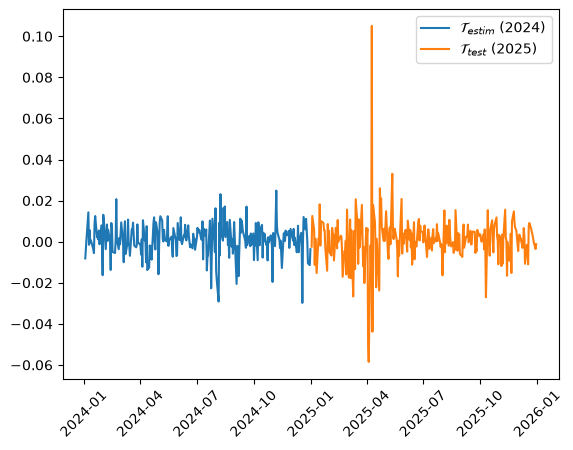

In [9]:
# Plot estimation and test sets
plot(x_estimation.index, x_estimation.values, label=r'$\mathcal{T}_{estim}$ (2024)')
plot(x_test.index, x_test.values, label=r'$\mathcal{T}_{test}$ (2025)')
legend()
xticks(rotation=45)
show()

In [ ]:
# Achieved up to this point
# 1. Downloaded daily SPY price data
# 2. Feature Extraction - pulling out the 'Close' prices
# 3. Linear Simple Return calculation using pct_change()
# 4. Data Validation with type/shape/index
# 5. Train/Test split
# 6. Visualisation of both sets

In [ ]:
# Next Steps
# The task is asking you to treat each of the 𝑡_𝑒𝑠𝑡𝑖𝑚 historical daily returns in x_estimation as equally likely
# — i.e. assign each observed return a probability of 1/𝑡_𝑒𝑠𝑡𝑖𝑚
# This is the "empirical" or "historical" distribution: you're not assuming any parametric model,
# you're just saying "the past 2024 daily returns are my scenario distribution, each equally weighted."
# The sample mean under uniform probabilities is just the familiar arithmetic average:

In [10]:
# uniform probabilities
# creating an array of length 't_estim' filled entirely with 1's
# Dividing he whole array by 't_estim' turn every 1 into '1/𝑡_𝑒𝑠𝑡𝑖𝑚'
# so p_1 now becomes an array like [1/251, 1/251, ..., 1/251] one probability value per day, equal in size.
# considering every historical daily return equally likely.  Or as the text says 'uniform probabilities'
p_1 = ones(t_estim) / t_estim

# Verify the shape of each array before multiplying they need to match, then this is a red flag
print(p_1.shape, x_estimation.shape)

# Sample mean = probability-weighted sum of returns
# x_estimation.values turns the Pandas series into a plain NumPy array of the actual daily return values
# p_1 * x_estimation.values multiplies element-wise each prob by its corresponding return
# since every probability is '1/𝑡_𝑒𝑠𝑡𝑖𝑚', this just scales each return down by '1/𝑡_𝑒𝑠𝑡𝑖𝑚'
# sum() adds all those scaled values together, which is actually the arithmetic mean of the 2024 returns (*weighted sum)
mu_hat_1 = sum(p_1 * x_estimation.values)
# printing the mean after rounding it to 3 decimal places
print('mu_hat_1 = ', mu_hat_1.round(3))

(251,) (251,)
mu_hat_1 =  0.001


In [11]:
# Just verifying that this gives me the same value as x_estimation.mean()
x_estimation.mean().round(3)


np.float64(0.001)

Task 3:

Assume the second scenario-probability distribution uses flexible probabilities with an exponential time decay.

In particular, set the half life THL to 3 months

Where [.] denotes the ceiling function [W]

tau_hl = 63

[  1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36
  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54
  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72
  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107 108
 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125 126
 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143 144
 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161 162
 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179 180
 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197 198
 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214 215 216
 217 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232 233 234
 235 236 237 238 239 240 241 242 243 2

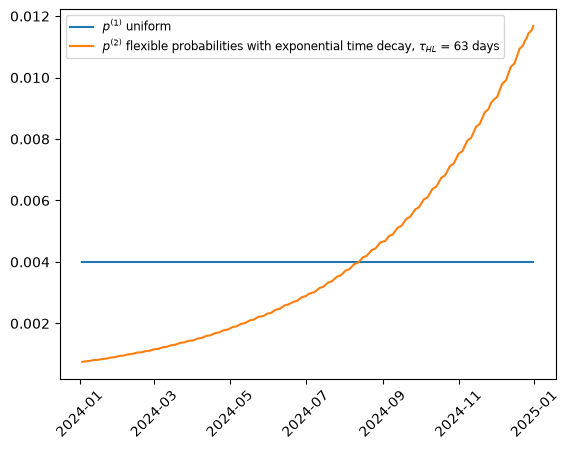


mu_hat_2 = 0.000645

mu_hat_1 = 0.000939

mu_hat_2 = 0.000645


In [13]:
# half life
# a quarter of the estimation window, rounded up (~3 months of trading days)
tau_hl = int(ceil(t_estim / 4))
print('tau_hl =', tau_hl)
print()

# time index t = 1, 2, 3, ...., t_estim (matching the formula's indexing)
t = arange(1, t_estim + 1)
print(t)
print()

# flexible probabilities with exponential time decay
# raw (un-normalised) exponential decay weights: most recent day -> exp(0) = 1
weights = exp(-log(2) / tau_hl * (t_estim - t))
# normalise so the probabilities sum to 1 (this is the denominator of the formula)
p_2 = weights / sum(weights)
print(f"The size of 'p_2' is = ", len(p_2))
print()
print("The first 5 values of 'p_2' : ", p_2[:5])
print()
print("The last 5 values of 'p_2' : ", p_2[-5:])
print()

# sanity check
print(p_2.shape, x_estimation.shape)
print()
print('the sum pf p_2 = ', sum(p_2))
print()
print('ratio last / one half-life back = ', p_2[-1] / p_2[-1 - tau_hl])
print()
print()

# plot of the probability profile
# plotting uniform vs exponential decay
plot(x_estimation.index, p_1, label='$p^{(1)}$ uniform')
plot(x_estimation.index, p_2, label='$p^{(2)}$ flexible probabilities with exponential time decay, $\\tau_{HL}$ = 63 days')
legend(fontsize='small');
xticks(rotation=45);
show()

# mean
# x_estim.values turns the Pandas Series into a Plain Numpy array of the actual daily return values
# p_2 * x_estim.values multiplies element-wise each prob byt its corresponding return
mu_hat_2 = sum(p_2 * x_estimation.values)
print()
print('mu_hat_2 =', mu_hat_2.round(6))
print()


# for verification
print('mu_hat_1 =', mu_hat_1.round(6))
print()
print('mu_hat_2 =', mu_hat_2.round(6))

Task 4:

Evaluate the performance of the two mean estimators
using the out-of-sample risk associated with the univariate squared loss.
In particular, prove that the sample mean is the estimator that performs the best.

In [14]:
# out-of-sample risks
# average squared loss over 2025 test set
# uniform probabilities on the test set; each 2025 day counts equally
p_test = ones(t_test) / t_test

# (x_test.values - mu_hat_1) -> each day's miss; **2 -> squared loss; weighted sum -> average
risk_1 = sum(p_test * (x_test.values - mu_hat_1) ** 2)
print()
print(f'risk for mu_hat_1 = {risk_1:.7e}')
print()
risk_2 = sum(p_test * (x_test.values - mu_hat_2) ** 2)
print(f'risk for mu_hat_2 = {risk_2:.7e}')
print()

# best performance
# the estimator with the lower risk....
best = 1 if risk_1 < risk_2 else 2
print(f'mu_hat_{best} is the estimator that performs the best.')
print()


risk for mu_hat_1 = 1.5045322e-04

risk for mu_hat_2 = 1.5043389e-04

mu_hat_2 is the estimator that performs the best.



Conclusion: #  The expected result of Mu1 having the better sample mean is not what was achieved.